In [1]:
import pickle, re, numpy as np, networkx as nx
import matplotlib.pyplot as plt

In [2]:
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.family'] = 'Arial'

# ============ 加载网络 ============
NET_DIR = r'E:\Claude\euclid-analysis\output\networks'

with open(f'{NET_DIR}/Human_Citation_Network.pkl', 'rb') as f:
    G_human = pickle.load(f)

G_ai = {}
for run in ['RunA', 'RunB', 'RunC']:
    with open(f'{NET_DIR}/{run}_AI_Citation_Network_Final.pkl', 'rb') as f:
        G_ai[run] = pickle.load(f)

In [3]:
all_props = sorted(
    [n for n in G_human.nodes() if re.fullmatch(r'\d+\.\d+', str(n).strip())],
    key=lambda x: (int(str(x).split('.')[0]), int(str(x).split('.')[1])))
print(f"Propositions: {len(all_props)}")

def jaccard(s1, s2):
    if not s1 and not s2:
        return 1.0
    if not s1 or not s2:
        return 0.0
    return len(s1 & s2) / len(s1 | s2)

def pairwise_jaccard(G1, G2, props):
    return np.array([
        jaccard(set(G1.successors(p)) if p in G1 else set(),
                set(G2.successors(p)) if p in G2 else set())
        for p in props])

networks = {'Human': G_human, 'A': G_ai['RunA'], 'B': G_ai['RunB'], 'C': G_ai['RunC']}

pairs_info = [
    ('A', 'Human', 'A-Human', '#08306b'),
    ('B', 'Human', 'B-Human', '#2171b5'),
    ('C', 'Human', 'C-Human', '#6baed6'),
    ('A', 'B',     'A-B',     '#67000d'),
    ('A', 'C',     'A-C',     '#cb181d'),
    ('B', 'C',     'B-C',     '#fb6a4a'),
]

results = {}
for n1, n2, label, _ in pairs_info:
    vals = pairwise_jaccard(networks[n1], networks[n2], all_props)
    results[label] = vals
    print(f"{label}: mean={vals.mean():.3f}, median={np.median(vals):.3f}")

Propositions: 465
A-Human: mean=0.374, median=0.357
B-Human: mean=0.375, median=0.333
C-Human: mean=0.372, median=0.333
A-B: mean=0.683, median=0.700
A-C: mean=0.677, median=0.667
B-C: mean=0.674, median=0.667


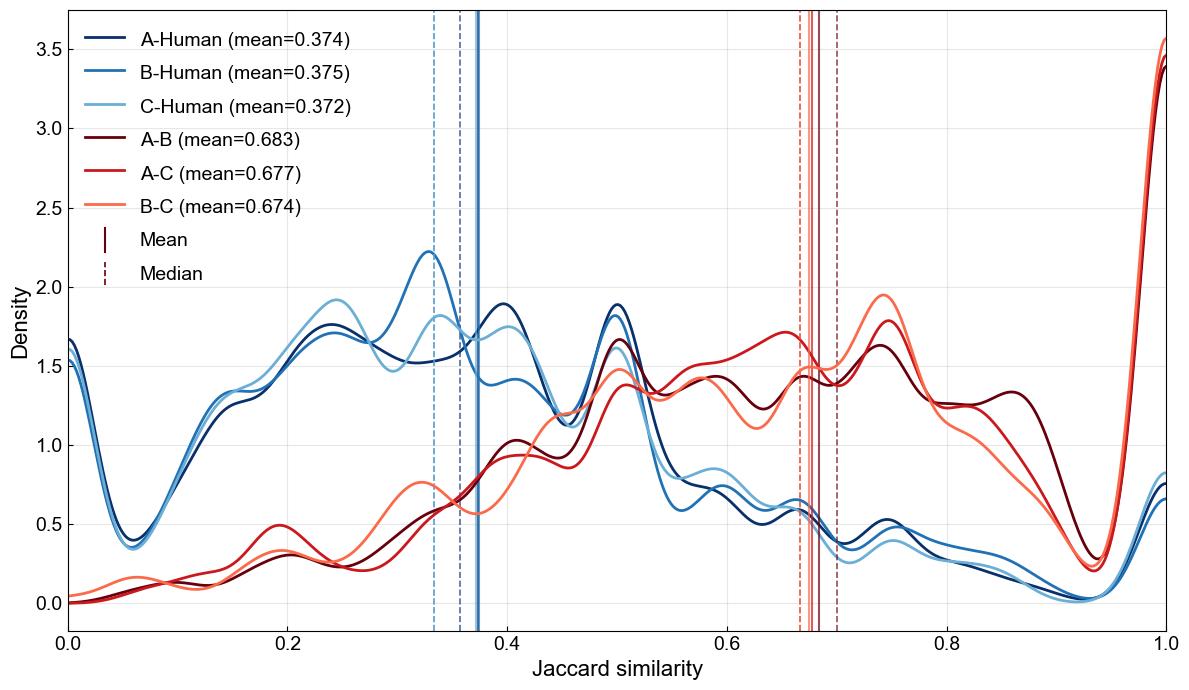

In [5]:
fig, ax = plt.subplots(figsize=(12, 7))
bins = np.arange(0, 1.05, 0.05)

from scipy.stats import gaussian_kde

for n1, n2, label, color in pairs_info:
    vals = results[label]
    m, md = vals.mean(), np.median(vals)
    xs = np.linspace(0, 1, 500)
    kde = gaussian_kde(vals, bw_method=0.1)
    ax.plot(xs, kde(xs), color=color, linewidth=2,
            label=f'{label} (mean={m:.3f})')
    ax.axvline(m,  color=color, ls='-',  lw=1.5, alpha=0.7)
    ax.axvline(md, color=color, ls='--', lw=1.2, alpha=0.7)

ax.set_xlabel('Jaccard similarity', fontsize=16)
ax.set_ylabel('Density', fontsize=16)
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=10, loc='upper left')
ax.set_xlim(0, 1)
ax.grid(alpha=0.3)
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

class VLineHandler(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        line = Line2D([width * 0.5, width * 0.5], [-ydescent, height - ydescent],
                      color=orig_handle.get_color(),
                      linestyle=orig_handle.get_linestyle(),
                      linewidth=orig_handle.get_linewidth(),
                      transform=trans)
        return [line]

mean_h   = Line2D([0], [0], color='#67000d', ls='-',  lw=1.5, label='Mean')
median_h = Line2D([0], [0], color='#67000d', ls='--', lw=1.2, label='Median')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + [mean_h, median_h], fontsize=14, loc='upper left',
          handler_map={mean_h: VLineHandler(), median_h: VLineHandler()},
          handleheight=1.5, frameon=False)

plt.tight_layout()
#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure1.pdf', dpi=300, bbox_inches='tight')
plt.show()